<a href="https://colab.research.google.com/github/amani-rahmani/Blood_Pressure_Analysis/blob/main/Blood_Pressure_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
df=pd.read_csv('/content/cardio_train.csv',sep=";")

In [3]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0.0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1.0
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1.0
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1.0
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0.0


In [5]:
df.shape

(49961, 13)

In [6]:
#you can also do it this way
print("Number of patients:", df.shape[0])

print("Number of columns:", df.shape[1])

Number of patients: 49961
Number of columns: 13


In [7]:
#to get the columns
print(df.columns.tolist())

['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49961 entries, 0 to 49960
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           49961 non-null  int64  
 1   age          49961 non-null  int64  
 2   gender       49961 non-null  int64  
 3   height       49961 non-null  int64  
 4   weight       49961 non-null  float64
 5   ap_hi        49961 non-null  int64  
 6   ap_lo        49961 non-null  int64  
 7   cholesterol  49961 non-null  int64  
 8   gluc         49961 non-null  int64  
 9   smoke        49961 non-null  int64  
 10  alco         49961 non-null  int64  
 11  active       49961 non-null  int64  
 12  cardio       49960 non-null  float64
dtypes: float64(2), int64(11)
memory usage: 5.0 MB


In [9]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49961.000000,49960.000000
mean,35676.161566,19464.684094,1.346971,164.366166,74.230610,128.747183,96.972118,1.363504,1.225856,0.088209,0.053402,0.802626,0.499039
std,20609.537461,2469.041025,0.476011,8.190134,14.327859,154.515534,200.225599,0.677197,0.572023,0.283601,0.224835,0.398021,0.500004
min,0.000000,10798.000000,1.000000,55.000000,11.000000,-150.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,17836.000000,17662.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,35682.000000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,53508.000000,21321.000000,2.000000,170.000000,82.000000,140.000000,90.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,71310.000000,23690.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
#checking for missing values
df.isnull().sum()

,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0


In [11]:
#checking for duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
print("systolic blood presure",df["ap_hi"].describe())

systolic blood presure count    49961.000000
mean       128.747183
std        154.515534
min       -150.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64


In [13]:
print("diastolic blood pressure",df["ap_lo"].describe())

diastolic blood pressure count    49961.000000
mean        96.972118
std        200.225599
min          0.000000
25%         80.000000
50%         80.000000
75%         90.000000
max      11000.000000
Name: ap_lo, dtype: float64


In [14]:
df["age_years"]=df["age"]/365.25
print(df["age_years"].head())

0    50.357290
1    55.381246
2    51.627652
3    48.249144
4    47.841205
Name: age_years, dtype: float64


In [16]:
blood_pressure_df=df[["id","age_years","gender","ap_hi","ap_lo","smoke", "alco"]].copy()
blood_pressure_df.head()

,id,age_years,gender,ap_hi,ap_lo,smoke,alco
0,0,50.357290,2,110,80,0,0
1,1,55.381246,1,140,90,0,0
2,2,51.627652,1,130,70,0,0
3,3,48.249144,2,150,100,0,0
4,4,47.841205,1,100,60,0,0


In [17]:
blood_pressure_df["gender"]=blood_pressure_df["gender"].map({1:"man",2:"woman"})
blood_pressure_df.head()

,id,age_years,gender,ap_hi,ap_lo,smoke,alco
0,0,50.357290,woman,110,80,0,0
1,1,55.381246,man,140,90,0,0
2,2,51.627652,man,130,70,0,0
3,3,48.249144,woman,150,100,0,0
4,4,47.841205,man,100,60,0,0


In [18]:
blood_pressure_df[["ap_hi", "ap_lo"]].describe()

,ap_hi,ap_lo
count,49961.000000,49961.000000
mean,128.747183,96.972118
std,154.515534,200.225599
min,-150.000000,0.000000
25%,120.000000,80.000000
50%,120.000000,80.000000
75%,140.000000,90.000000
max,16020.000000,11000.000000


In [20]:
print("Median systolic BP:",
      blood_pressure_df["ap_hi"].median())

print("Median diastolic BP:",
     blood_pressure_df["ap_lo"].median())

Median systolic BP: 120.0
Median diastolic BP: 80.0


In [21]:
blood_pressure_df["age_group"] = pd.cut(
    blood_pressure_df["age_years"],
    bins=[18, 30, 40, 50, 60, 70, 120],
    labels=["18-29", "30-39", "40-49",
            "50-59", "60-69", "70+"],
    right=False
)

In [22]:
blood_pressure_df["smoking_label"] = blood_pressure_df["smoke"].map({
    0: "Non-smoker",
    1: "Smoker"
})

In [23]:
blood_pressure_df["alcohol_label"] =blood_pressure_df["alco"].map({
    0: "No reported consumption",
    1: "Reported consumption"
})

In [25]:
blood_pressure_df.head()

,id,age_years,gender,ap_hi,ap_lo,smoke,alco,age_group,smoking_label,alcohol_label
0,0,50.357290,woman,110,80,0,0,50-59,Non-smoker,No reported consumption
1,1,55.381246,man,140,90,0,0,50-59,Non-smoker,No reported consumption
2,2,51.627652,man,130,70,0,0,50-59,Non-smoker,No reported consumption
3,3,48.249144,woman,150,100,0,0,40-49,Non-smoker,No reported consumption
4,4,47.841205,man,100,60,0,0,40-49,Non-smoker,No reported consumption


In [31]:
clean_df = blood_pressure_df[
    (blood_pressure_df["ap_hi"].between(70, 250)) &
    (blood_pressure_df["ap_lo"].between(40, 150)) &
    (blood_pressure_df["ap_hi"] > blood_pressure_df["ap_lo"])
].copy()

print("Original records:", len(blood_pressure_df))
print("Records after cleaning:", len(clean_df))
print("Records excluded:", len(blood_pressure_df) - len(clean_df))

Original records: 49961
Records after cleaning: 49003
Records excluded: 958


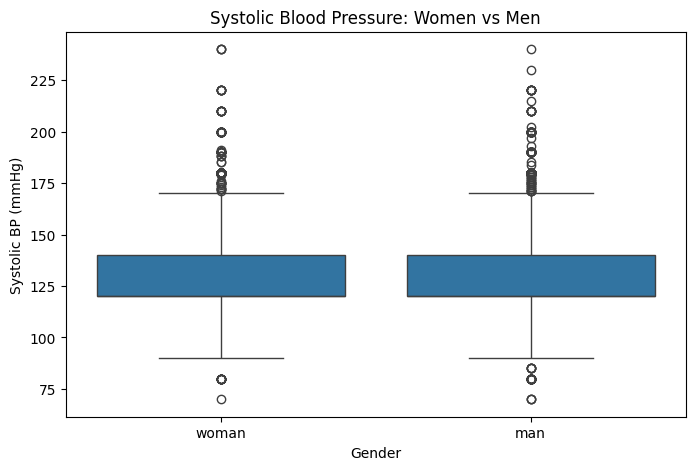

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="gender",
    y="ap_hi",
    order=["woman", "man"]
)

plt.title("Systolic Blood Pressure: Women vs Men")
plt.xlabel("Gender")
plt.ylabel("Systolic BP (mmHg)")

plt.show()

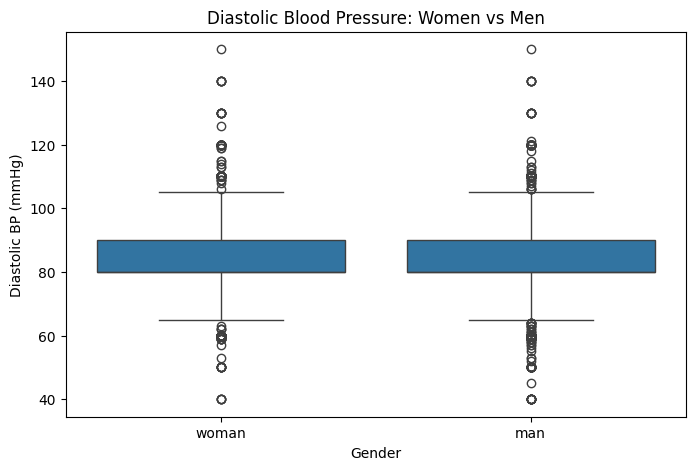

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="gender",
    y="ap_lo",
    order=["woman", "man"]
)

plt.title("Diastolic Blood Pressure: Women vs Men")
plt.xlabel("Gender")
plt.ylabel("Diastolic BP (mmHg)")

plt.show()

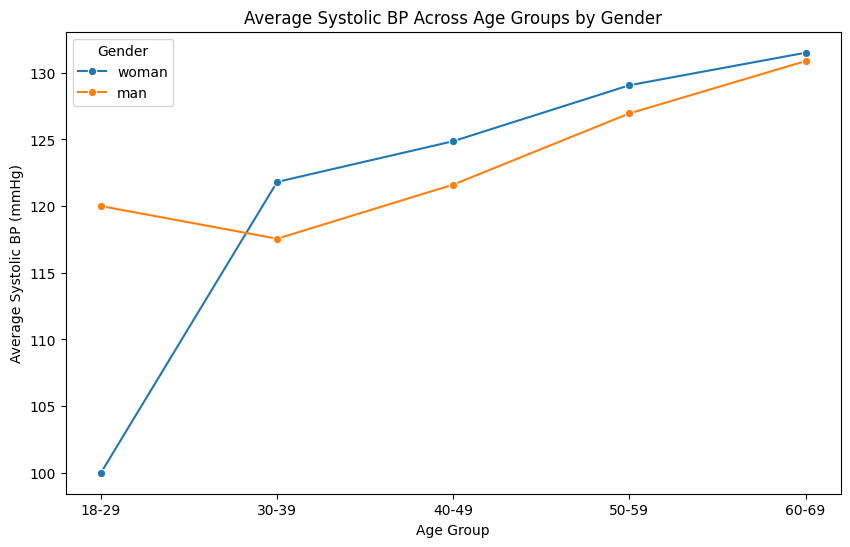

In [36]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=clean_df,
    x="age_group",
    y="ap_hi",
    hue="gender",
    marker="o",
    errorbar=None
)

plt.title("Average Systolic BP Across Age Groups by Gender")
plt.xlabel("Age Group")
plt.ylabel("Average Systolic BP (mmHg)")
plt.legend(title="Gender")

plt.show()

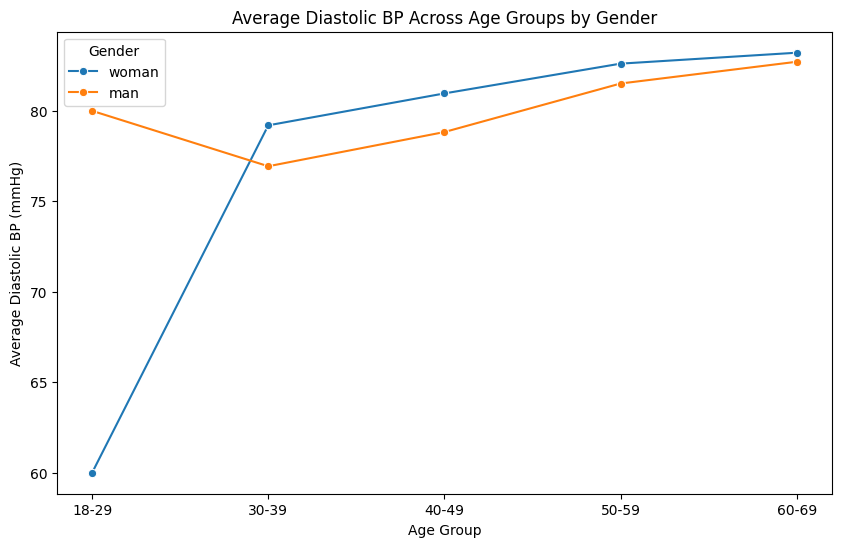

In [37]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=clean_df,
    x="age_group",
    y="ap_lo",
    hue="gender",
    marker="o",
    errorbar=None
)

plt.title("Average Diastolic BP Across Age Groups by Gender")
plt.xlabel("Age Group")
plt.ylabel("Average Diastolic BP (mmHg)")
plt.legend(title="Gender")

plt.show()